# Ovarian-cancer forecasting tool: usage examples
Synthetic data only (patient SYN38). Time is in months; recurrence intervals are in months
after the end of adjuvant chemotherapy (ACT) unless stated otherwise. The fits here use few
particles to run quickly, so results carry some Monte Carlo noise.

| Section | Contents |
|---|---|
| 0 | Setup; input format: a `PatientRecord` from synthetic data or from your own arrays |
| 1 | Profile: defaults, changing a prior, error messages |
| 2 | Fit at one time point: `fit` → `Snapshot`, report and parameter table |
| 3 | A new reading: `step`, `shrinkage` |
| 4 | Visit-by-visit replay: `replay` → `History`, tables and every figure |
| 5 | Plotting API: options, saving, editing a figure |
| 6 | Options: time decay, censoring, fixed σ, threshold acceptance |

## 0 · Setup
Run from the repository root. Loads the synthetic data and the tool.

In [1]:
%matplotlib inline
from copy import deepcopy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
from IPython.display import display
from ovca import Forecaster, PatientRecord, default_profile, check_profile, ProfileError
from ovca.profile import prior_table

set_matplotlib_formats("png")
plt.rcParams["figure.dpi"] = 80
data = pd.read_csv(Path("data") / "synthetic_data.csv")
record = PatientRecord.from_synthetic(data, "SYN38")
display(record.table())

,month,ca125,phase
0,0.000000,565.83900,pre
1,2.000000,225.52500,pre
2,3.000000,128.37400,pre
3,4.900000,51.55230,pre
4,5.500000,6.97347,post
5,6.000000,6.70015,post
6,8.000000,4.81960,post
7,10.000000,3.22581,post
8,11.000000,2.10923,post
9,14.033333,3.01780,post


**Input format.** One patient = readings (month, CA-125) + the frontline schedule (start
month of each NACT cycle, month of surgery, start month of each ACT cycle; each cycle is on
for one month by default). For your own data use `PatientRecord.from_arrays`. `t_stop`
(second-line treatment or maintenance starts) and `t_recurrence` (observed recurrence,
absolute month) are optional and are drawn on the figures. The numbers below are made up,
only to show the format.

In [2]:
my_record = PatientRecord.from_arrays(
    "DEMO", t_months=[0, 1, 2, 3.4, 4.5, 5.5, 7, 9, 12],
    ca125=[900, 400, 180, 95, 12, 8, 6, 9, 15],
    nact_starts=[0, 1, 2], t_surgery=4, act_starts=[5, 6, 7],
    t_stop=np.inf, t_recurrence=np.nan)
print(my_record.schedule)
print("end of ACT:", my_record.schedule.t_end)
display(my_record.table())

Schedule(nact_starts=array([0., 1., 2.]), t_surgery=4.0, act_starts=array([5., 6., 7.]), duration=1.0)
end of ACT: 8.0


,month,ca125,phase
0,0.0,900.0,pre
1,1.0,400.0,pre
2,2.0,180.0,pre
3,3.4,95.0,pre
4,4.5,12.0,post
5,5.5,8.0,post
6,7.0,6.0,post
7,9.0,9.0,post
8,12.0,15.0,post


## 1 · Profile and checks
The default profile lists every prior and algorithm setting. The check prints the resolved
priors and marks the ones you changed; a wrong profile gives a message naming the problem.

In [3]:
profile = default_profile()
checked = check_profile(profile)
display(prior_table(checked))

profile: backend = abc, model = growth_death, surgery shifts ['gamma', 'delta'], abc acceptance = likelihood
  parameter                                                  prior  set_by                                                                 meaning
  gamma_pre lognormal(median 0.1, sd_log 0.7); 80%: 0.0408 – 0.245 default                                    model parameter gamma before surgery
  delta_pre   lognormal(median 0.8, sd_log 0.5); 80%: 0.421 – 1.52 default                                    model parameter delta before surgery
shift_gamma            normal(mean 0, sd 0.6); 80%: -0.769 – 0.769 default   surgery effect on gamma: log gamma_post = log gamma_pre + shift_gamma
shift_delta            normal(mean 0, sd 0.6); 80%: -0.769 – 0.769 default   surgery effect on delta: log delta_post = log delta_pre + shift_delta
  level_pre             lognormal(median = that reading, sd_log 1) default                   tumour burden at the first pre-surgery reading (U/mL)
 level_po

,parameter,prior,set_by,meaning
0,gamma_pre,"lognormal(median 0.1, sd_log 0.7); 80%: 0.0408...",default,model parameter gamma before surgery
1,delta_pre,"lognormal(median 0.8, sd_log 0.5); 80%: 0.421 ...",default,model parameter delta before surgery
2,shift_gamma,"normal(mean 0, sd 0.6); 80%: -0.769 – 0.769",default,surgery effect on gamma: log gamma_post = log ...
3,shift_delta,"normal(mean 0, sd 0.6); 80%: -0.769 – 0.769",default,surgery effect on delta: log delta_post = log ...
4,level_pre,"lognormal(median = that reading, sd_log 1)",default,tumour burden at the first pre-surgery reading...
5,level_post,"lognormal(median = that reading, sd_log 1)",default,tumour burden at the first post-surgery readin...
6,sigma,"lognormal(median 0.15, sd_log 0.5); 80%: 0.079...",default,observation error: sd of log CA-125 around the...


In [4]:
profile["priors"]["gamma_pre"] = {"dist": "lognormal", "median": 0.08, "sd_log": 0.7}
# Keep the demonstration quick.
profile["abc"].update(n_particles=300, n_moves=10)
profile["forecast"].update(n_draws=600, step=0.2)
profile = check_profile(profile, verbose=False)
display(prior_table(profile))

wrong = deepcopy(profile)
wrong["priors"]["gamma_pre"] = {"dist": "lognormal", "median": 0.08, "sd_lg": 0.7}
try:
    check_profile(wrong, verbose=False)
except ProfileError as exc:
    print(exc)

,parameter,prior,set_by,meaning
0,gamma_pre,"lognormal(median 0.08, sd_log 0.7); 80%: 0.032...",you,model parameter gamma before surgery
1,delta_pre,"lognormal(median 0.8, sd_log 0.5); 80%: 0.421 ...",default,model parameter delta before surgery
2,shift_gamma,"normal(mean 0, sd 0.6); 80%: -0.769 – 0.769",default,surgery effect on gamma: log gamma_post = log ...
3,shift_delta,"normal(mean 0, sd 0.6); 80%: -0.769 – 0.769",default,surgery effect on delta: log delta_post = log ...
4,level_pre,"lognormal(median = that reading, sd_log 1)",default,tumour burden at the first pre-surgery reading...
5,level_post,"lognormal(median = that reading, sd_log 1)",default,tumour burden at the first post-surgery readin...
6,sigma,"lognormal(median 0.15, sd_log 0.5); 80%: 0.079...",default,observation error: sd of log CA-125 around the...


profile has 2 problem(s):
  - priors.gamma_pre: lognormal takes ['median', 'sd_log'], not 'sd_lg' (did you mean 'sd_log'?)
  - priors.gamma_pre: lognormal needs ['sd_log']


## 2 · Forecast at the end of ACT
Fit with the readings up to the end of ACT only. The report gives the recurrence interval and
the suggested next visit; the summary gives posterior quantiles of every parameter. The black
dashed line in the figure is the synthetic truth, for comparison. Draws that do not recur
within the horizon have recurrence = inf; `report()` caps the interval at horizon + 1.

patient                                        SYN38
t_now                                           11.0
n_readings                                         9
backend                                          abc
recurrence_low                             24.287284
recurrence_median                               37.0
recurrence_high                                 37.0
recurrence_level                                 0.8
recurrence_capped_at                            37.0
p_recur_6mo                                      0.0
p_recur_12mo                                   0.005
next_visit                                      17.0
band_at_next_visit      (2.3692, 2.899376, 4.427568)
seconds                                     0.029519
Name: end of ACT, dtype: object

,parameter,q10,q50,q90
0,gamma_pre,0.025379,0.049308,0.094386
1,delta_pre,0.772218,0.850723,0.946405
2,gamma_post,0.019217,0.046520,0.112441
3,delta_post,0.406059,0.477374,0.595748
4,shift_gamma,-0.666077,-0.033546,0.576315
5,shift_delta,-0.737349,-0.570639,-0.391045
6,level_pre,480.471993,539.946028,598.362484
7,level_post,6.168114,6.755393,7.345336
8,ca125_0,480.471993,539.946028,598.362484
9,surgery_jump,0.103341,0.120419,0.138535


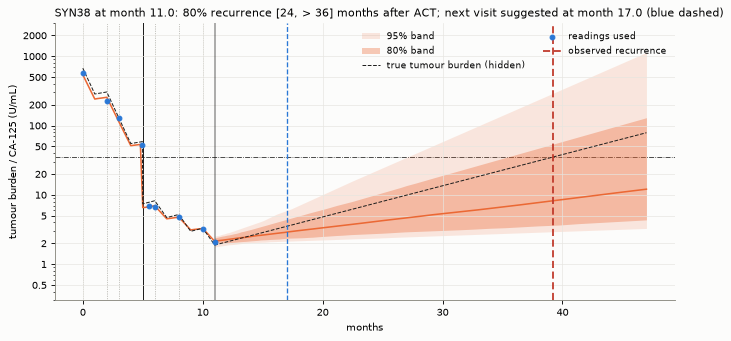

In [5]:
end_act = record.schedule.t_end
observed = record.upto(end_act)
forecaster = Forecaster(profile)
snap = forecaster.fit(observed, t_now=end_act)
# report(): recurrence_low/median/high = 80% interval (months after ACT; capped at horizon + 1),
# p_recur_6mo / 12mo, next_visit (month), band_at_next_visit (tumour 80% band there)
display(pd.Series(snap.report(), name="end of ACT"))
display(snap.summary())
snap.plot()
plt.show()

## 3 · A new reading
Add the next synthetic follow-up reading and refit; compare interval widths and how
surprising the new reading was. Intervals do not always shrink after every reading.

In [6]:
# The snapshot contains only observed visits, so the new visit is added once.
next_index = np.flatnonzero(record.t > end_act)[0]
t_new, y_new = record.t[next_index], record.y[next_index]
updated = forecaster.step(snap, t_new, y_new)
assert updated.previous is snap
display(pd.Series(updated.shrinkage(), name="before vs after"))

t_before                   11.000000
t_after                    14.033333
at                         17.000000
band_ratio_before           1.868803
band_ratio_after            1.730686
recurrence_width_before    12.712716
recurrence_width_after     17.489118
new_reading_month          14.033333
new_reading                 3.017800
pit                         0.786667
surprise                    0.426667
Name: before vs after, dtype: float64

## 4 · Visit-by-visit replay
Refit after every visit from the second one on, using only the readings available at that
time, and see how the forecast and the parameter posteriors change.

In [7]:
history = forecaster.replay(record, verbose=False)
assert len(history) == len(record.t) - 1
display(history.table())
display(history.parameter_table().head(12))

,t_now,rec_low,rec_median,rec_high,rec_width,next_visit,seconds,observed_recurrence,observed_in_interval,band_ratio_next,surprise_new_reading
0,2.000000,NaN,NaN,NaN,NaN,NaN,0.009355,28.18,None,2.629948,NaN
1,3.000000,NaN,NaN,NaN,NaN,NaN,0.011124,28.18,None,NaN,0.446667
2,4.900000,NaN,NaN,NaN,NaN,NaN,0.013197,28.18,None,NaN,NaN
3,5.500000,18.592588,37.000000,37.000000,18.407412,11.500000,0.021157,28.18,True,1.533055,NaN
4,6.000000,23.601815,37.000000,37.000000,13.398185,12.000000,0.024045,28.18,True,4.060848,0.730000
5,8.000000,15.960142,37.000000,37.000000,21.039858,14.000000,0.023348,28.18,True,1.918175,0.313333
6,10.000000,19.561961,37.000000,37.000000,17.438039,16.000000,0.027066,28.18,True,1.567171,0.926667
7,11.000000,24.925377,37.000000,37.000000,12.074623,17.000000,0.027317,28.18,True,1.482033,0.760000
8,14.033333,20.442509,37.000000,37.000000,16.557491,20.033333,0.026931,28.18,True,1.882993,0.353333
9,17.233333,21.375479,26.939607,37.000000,15.624521,23.233333,0.030195,28.18,True,1.643442,0.493333


,t_now,parameter,q10,q25,q50,q75,q90
0,2.0,gamma_pre,0.026952,0.040101,0.067359,0.115380,0.174315
1,2.0,delta_pre,0.690967,0.838502,0.993477,1.152610,1.335531
2,2.0,gamma_post,NaN,NaN,NaN,NaN,NaN
3,2.0,delta_post,NaN,NaN,NaN,NaN,NaN
4,2.0,shift_gamma,NaN,NaN,NaN,NaN,NaN
5,2.0,shift_delta,NaN,NaN,NaN,NaN,NaN
6,2.0,level_pre,438.852350,485.627854,546.956566,600.690047,668.307286
7,2.0,level_post,NaN,NaN,NaN,NaN,NaN
8,2.0,ca125_0,438.852350,485.627854,546.956566,600.690047,668.307286
9,2.0,surgery_jump,NaN,NaN,NaN,NaN,NaN


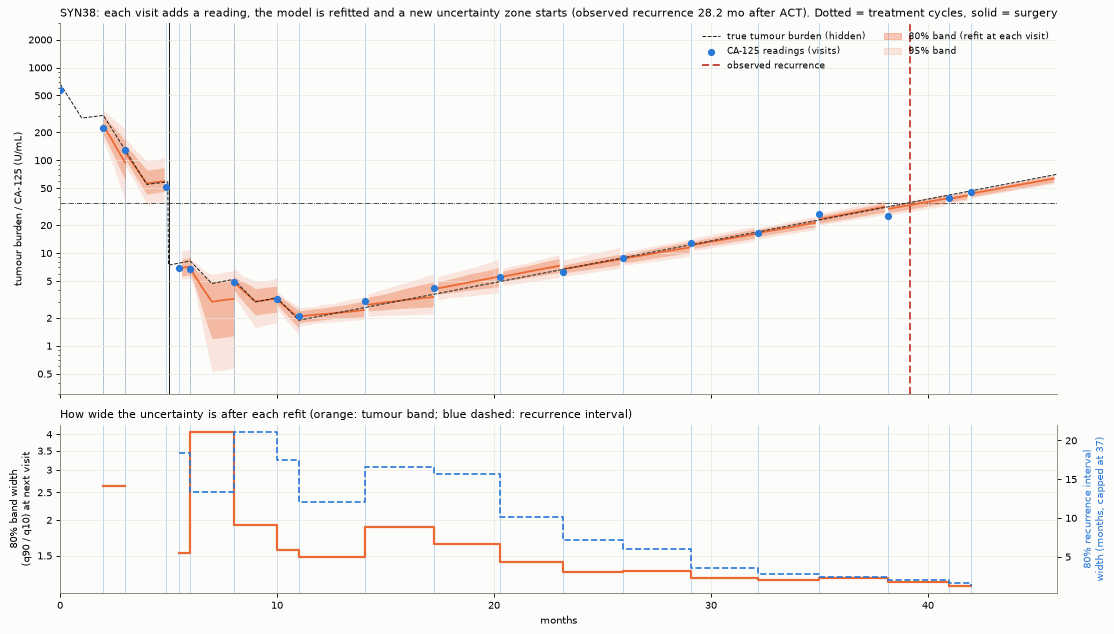

In [8]:
history.plot_tube()
plt.show()

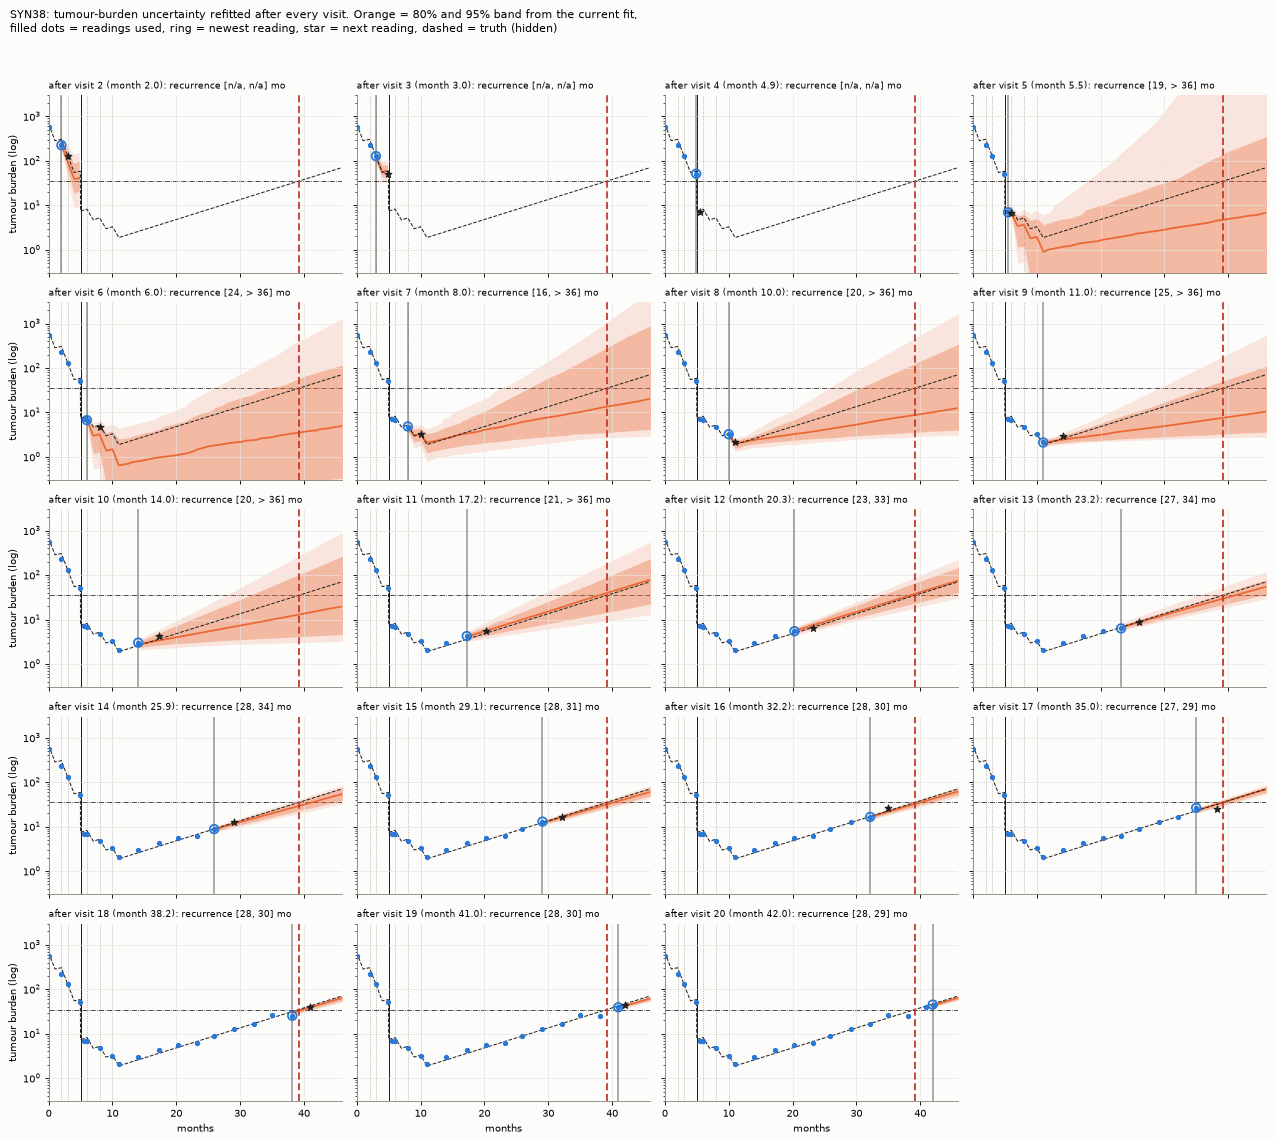

In [9]:
history.plot_panels()
plt.show()

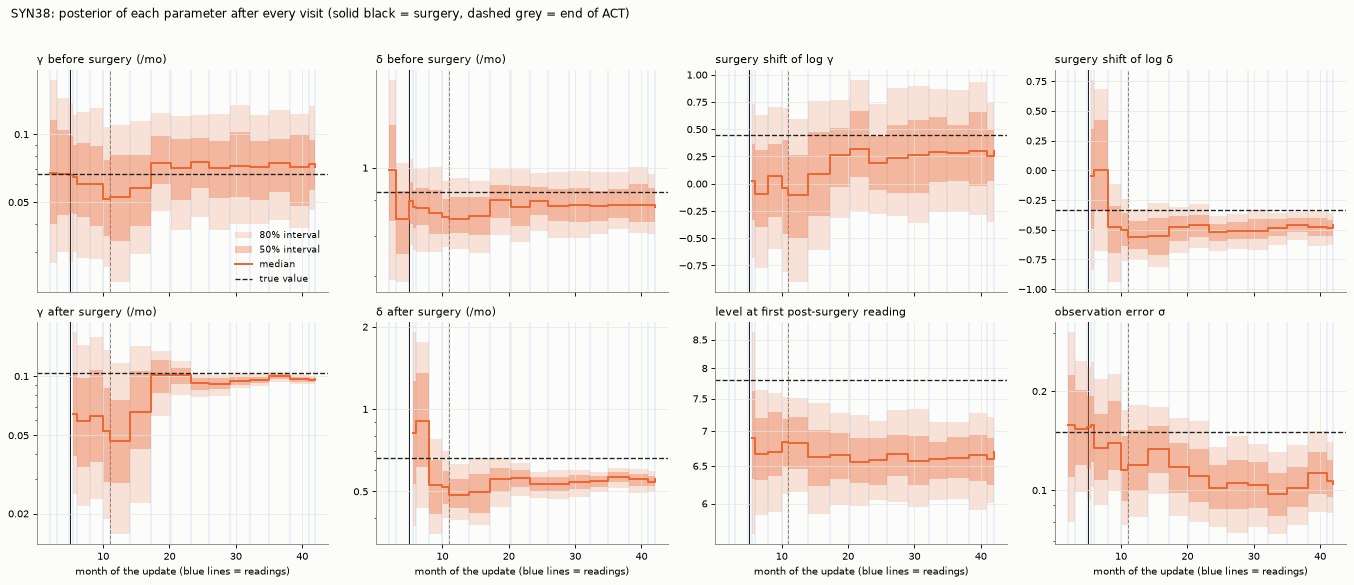

In [10]:
history.plot_parameters()
plt.show()

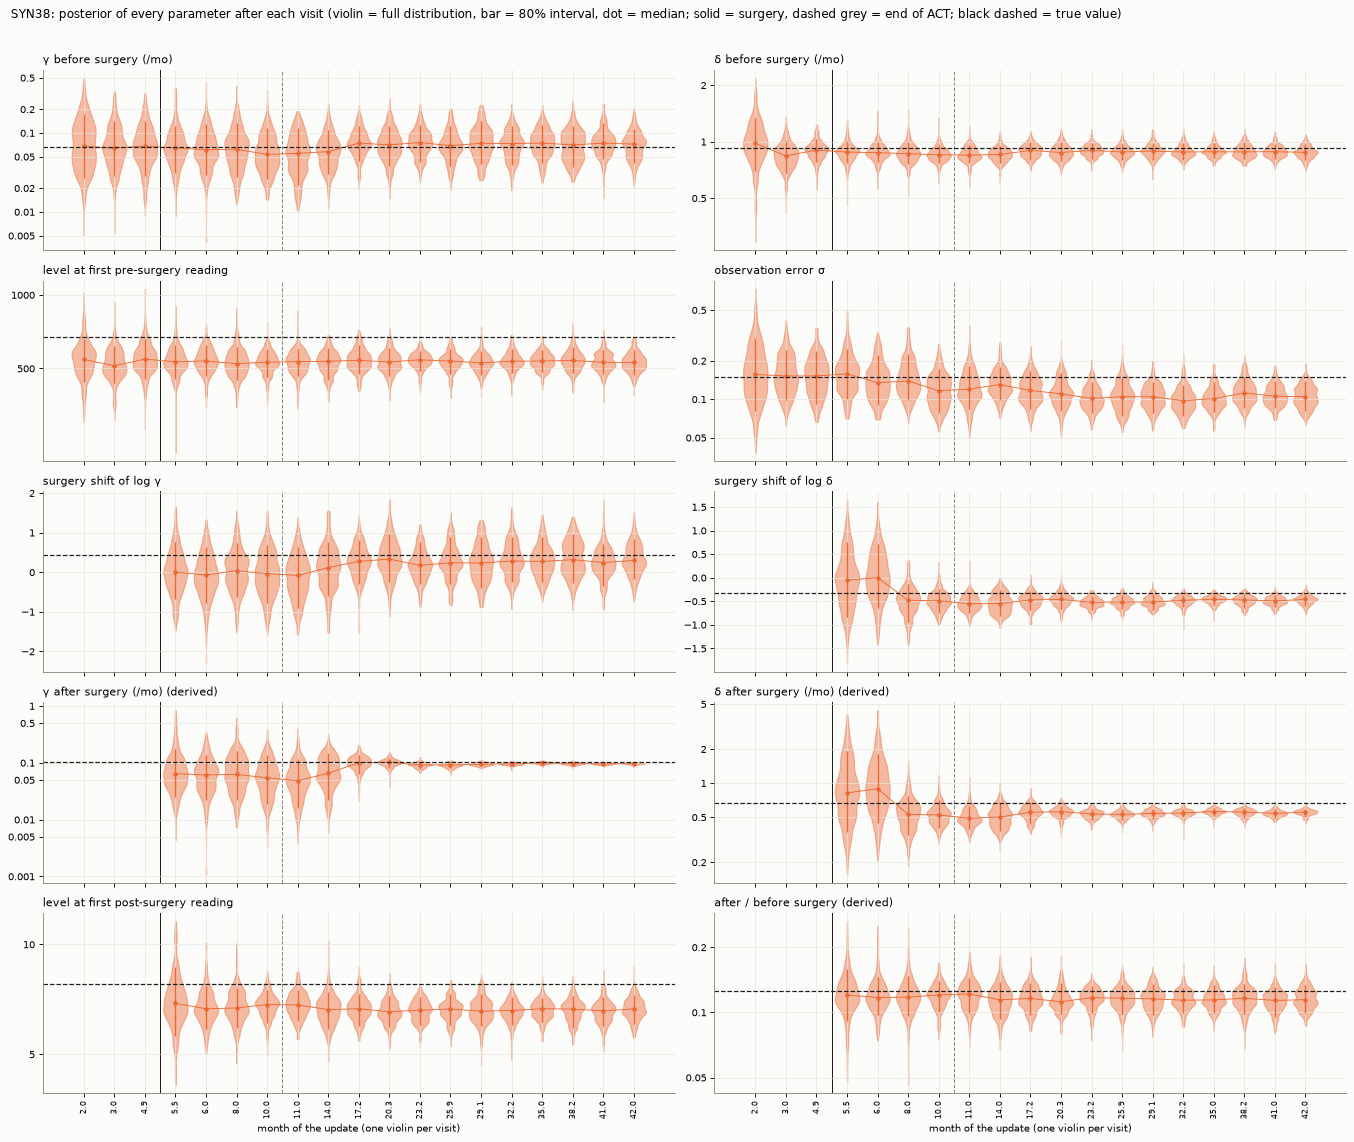

In [11]:
history.plot_parameter_distributions()
plt.show()

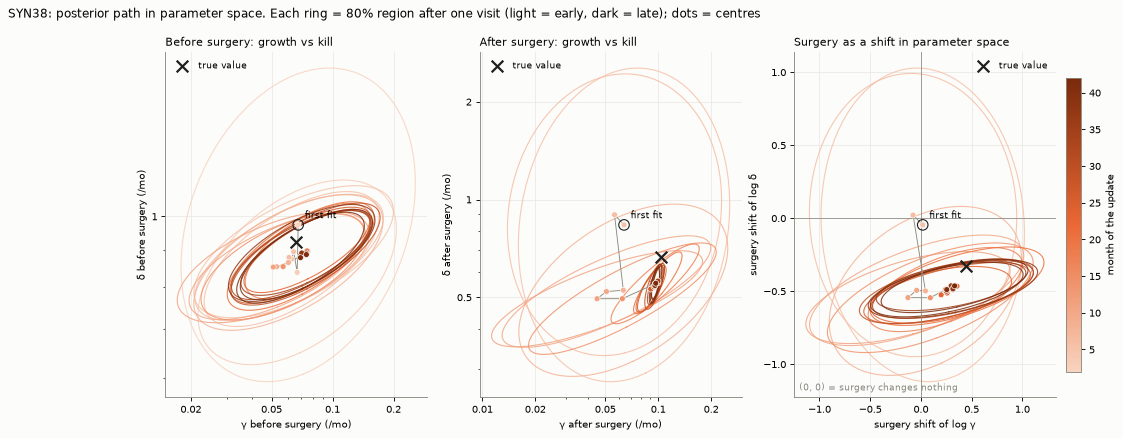

In [12]:
history.plot_parameter_space()
plt.show()

## 5 · Plotting API
Every figure is a method of `History` or `Snapshot`. It returns the matplotlib figure and also
saves it when given a path.

| Method | Figure | Common options |
|---|---|---|
| `hist.plot_tube(path)` | Overview: forecast band per segment + how wide it is | `reference` |
| `hist.plot_panels(path)` | One panel per refit | `reference`, `ncol` |
| `hist.plot_parameters(path)` | Median and 50% / 80% interval of each parameter over time | `params` |
| `hist.plot_parameter_distributions(path)` | Full posterior of each parameter after every visit (violins) | `params`, `n` |
| `hist.plot_parameter_space(path)` | Path in parameter space (80% ellipses) | `pairs` |
| `snap.plot(path)` | Forecast at one time point | `noisy` |

`reference` (black dashed line): `"auto"` (synthetic = truth, real = `"forecast"`),
`"forecast"` (median of the fit to the readings so far), `"hindsight"` (fit once the next
reading is in), `"fit"` (fit to all readings), `"none"`.

['post.png', 'tube.png']


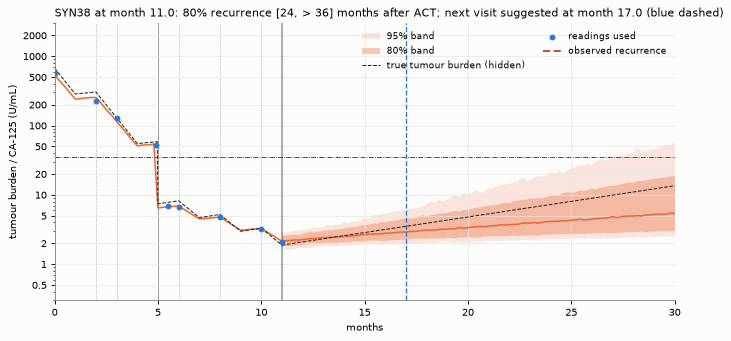

In [13]:
import tempfile
out = Path(tempfile.mkdtemp())
# model fit instead of the truth as the dashed line; only three parameters; save to files
history.plot_tube(out / "tube.png", reference="forecast")
history.plot_parameter_distributions(out / "post.png",
                                     params=["gamma_post", "delta_post", "sigma"])
plt.close("all")
print(sorted(p.name for p in out.iterdir()))

# a figure can be changed afterwards
fig = snap.plot(noisy=True)          # band for the readings (with sigma), not the tumour
fig.axes[0].set_xlim(0, 30)
plt.show()

## 6 · Options
Compared at the same time point (end of ACT): time decay of old readings, readings below 35
treated as censored, fixed observation error, and threshold acceptance (which needs a fixed
sigma). The table gives each fit's 80% recurrence interval and median in months after ACT;
`inf` means beyond that fit's horizon. Small settings, for demonstration only.

In [14]:
variants = {}
decay = deepcopy(profile)
decay["data"]["decay_tau"] = 12.0
variants["time decay (tau = 12 months)"] = decay

censored = deepcopy(profile)
censored["data"]["censor_below"] = 35
variants["censored below 35"] = censored

fixed = deepcopy(profile)
fixed["priors"]["sigma"] = 0.15
variants["fixed sigma = 0.15"] = fixed

threshold = deepcopy(fixed)
threshold["abc"].update(acceptance="threshold", max_generations=8,
                        max_sims_per_gen=6000, batch=600)
variants["threshold acceptance (fixed sigma)"] = threshold

rows = []
for label, option in variants.items():
    option_snap = Forecaster(option).fit(observed, t_now=end_act)
    low, median, high = option_snap.recurrence_interval()
    rows.append({"setting": label, "low (10%)": low, "median": median, "high (90%)": high})
display(pd.DataFrame(rows).set_index("setting").round(2))

,low (10%),median,high (90%)
setting,,,
time decay (tau = 12 months),23.57,inf,inf
censored below 35,19.01,inf,inf
fixed sigma = 0.15,17.82,inf,inf
threshold acceptance (fixed sigma),10.82,inf,inf
